In [1]:
#####     Random Forest Model and SHAP Analysis     #####
from pathlib import Path
from string import ascii_lowercase
import warnings
import hashlib

import numpy as np
import pandas as pd
from joblib import load, dump
import rasterio

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm, LinearSegmentedColormap
from matplotlib.patches import Patch
import cartopy.crs as ccrs

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor as VIF
from statsmodels.nonparametric.smoothers_lowess import lowess

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import shap

RANDOM_SEED = 42

lat, lon = np.arange(-90, 90.1, 1), np.arange(0, 360.1, 1)
ROOT = Path("./")
OUT_DIR = ROOT
OUT_DIR.mkdir(parents=True, exist_ok=True)

def flipImage(tiff: np.ndarray, shift=180) -> np.ndarray:
    """Flip latitude and shift longitude from original raster layout to 0-360° layout."""
    flipped = np.flip(tiff, axis=0)  # 纬度翻转
    shifted = np.roll(flipped, -shift, axis=1)  # 经度平移
    return shifted

def CheckVIF(data: np.ndarray, names: list[str], vif_thr: float = 10., protected: list[str] = []):
    """Iteratively remove the non-protected variable with the largest VIF if it exceeds threshold."""
    # Calculate VIF
    X = sm.add_constant(data)
    vifs = np.array([VIF(X, i) for i in range(1, X.shape[1])])
    # Filter out protected variables
    protected = [] if protected is None else protected
    for p in protected:
        if not p in names:  print(f" > Warning: Variable {p} not found!")
    not_removable = np.array([(name in protected) for name in names])
    vifs[not_removable] = -np.inf
    # Remove the variable with the largest VIF
    max_vif, idx = np.max(vifs), np.argmax(vifs)
    if max_vif < vif_thr:
        print(f"END. Remain Vars: {len(names)}")
        return True, data, names
    print(f"Var {names[idx]} eliminated. VIF: {max_vif:.2f}")
    return False, np.delete(data, idx, axis=1), np.delete(names, idx, axis=0).tolist()

def LinearRegTest(X: np.ndarray, Y: np.ndarray):
    print("Linear Regression")
    model = LinearRegression()
    model.fit(X, Y)
    r2 = model.score(X, Y)
    rmse = np.sqrt(np.mean((model.predict(X) - Y)**2))
    print(f"R2 = {r2:.4f},  RMSE = {rmse:.4f}")

def panel_label(ax, label: str):
    label = f"({label})"
    ax.text(0.02, 1.05, label, transform=ax.transAxes, ha="left", va="top",
            fontsize=12, fontweight="bold", zorder=10,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.5, pad=1.0))


In [2]:
### ----- Load ESACCI V7 / CMIP6 / Koppen / clusters ----- ###
ESAv7_data = np.load(ROOT / "Data" / "AGBC_ESAv7.npz")
ESAv7_std = np.load(ROOT / "Data" / "AGBCsd_ESAv7.npz")
ESAv7_data = {k.title(): flipImage(v.astype(np.float32)) for k, v in ESAv7_data.items()}
ESAv7_std = {k.title(): flipImage(v.astype(np.float32)) for k, v in ESAv7_std.items()}
ESA_data = ESAv7_data["Mean"].copy()
ESA_std = ESAv7_std["Mean"].copy()

CMIP_set = np.load(ROOT / "Data" / "CMIP6_AGBC.npz")
modelNames = list(CMIP_set.keys())
CMIP_data = np.stack([np.array(CMIP_set[name], dtype=np.float32) for name in modelNames], axis=0)
modelNum = len(modelNames)
print(f"CMIP Models: {modelNum}")

with rasterio.open(ROOT / "Data" / "Koppen_2010.tif", "r") as src:
    Koppen = flipImage(src.read(1).astype(np.float32))

ValidMask = (Koppen > 0) & (ESA_data > 0)
TreeMask = load(ROOT / "Data" / "Masks" / "treemask.joblib").astype(bool)
TreeMask &= ValidMask
ESA_datat = ESA_data.copy()
ESA_datat[~TreeMask] = np.nan
CMIP_datat = CMIP_data.copy()
CMIP_datat[:, ~TreeMask] = np.nan

cluster_df = pd.read_csv(ROOT / "cluster.csv", header=0)
cluster_df["Cluster"] = cluster_df["Cluster"].astype(int)
cluster_map = cluster_df.set_index("Model")["Cluster"].to_dict()
cluster_ids = sorted(cluster_df["Cluster"].unique())

missing = sorted(set(modelNames) - set(cluster_map))
if missing:
    raise ValueError(f"Models missing from `cluster.csv`: {missing}")

model_groups = {"MME Mean": modelNames}
for cid in cluster_ids:
    model_groups[f"Cluster {cid}"] = cluster_df.loc[cluster_df["Cluster"] == cid, "Model"].tolist()

for label, names in model_groups.items():
    print(f"{label}: N={len(names)}")


CMIP Models: 30
MME Mean: N=30
Cluster 1: N=15
Cluster 2: N=5
Cluster 3: N=8
Cluster 4: N=2


In [3]:
### ----- Load explanatory variables ----- ###
clim_name = [
    "Tmean", "MDR", "ISO", "Tssn", "Tmax", "Tmin", "TAR", "TWeQ", "TDrQ", "TWaQ", "TCoQ",
    "Prec", "PWM", "PDM", "Pssn", "PWeQ", "PDrQ", "PWaQ", "PCoQ",
]
var_clim = load(ROOT / "Data" / "Vars" / "VarClim.joblib")
var_soil1 = load(ROOT / "Data" / "Vars" / "VarSoil_face.joblib")
var_soil2 = load(ROOT / "Data" / "Vars" / "VarSoil_sub.joblib")
var_veg = load(ROOT / "Data" / "Vars" / "VarVeg.joblib")

vars_list, vars_name, vars_group = [], [], []
for key, val in var_clim.items():
    idx = len(vars_list)
    vars_list.append(val.astype(np.float32))
    vars_name.append(f"{key} ({clim_name[idx]})")
    vars_group.append("Climate")
for key, val in var_soil1.items():
    vars_list.append(val.astype(np.float32))
    vars_name.append(key.replace("_face", "_top"))  # Rename topsoil variables
    vars_group.append("Soil")
for key, val in var_soil2.items():
    vars_list.append(val.astype(np.float32))
    vars_name.append(key)
    vars_group.append("Soil")
for key, val in var_veg.items():
    vars_list.append(val.astype(np.float32))
    vars_name.append(key)
    vars_group.append("Vegetation")

num_clim = sum(g == "Climate" for g in vars_group)
num_soil = sum(g == "Soil" for g in vars_group)
num_veg = sum(g == "Vegetation" for g in vars_group)
Variables_all = np.stack(vars_list, axis=0)  # (V, lat, lon)
print(f"Variables: {len(vars_name)}")
print(f"Clim: {num_clim},  Soil: {num_soil},  Veg: {num_veg}")

### ----- VIF filtering ----- ###
RUN_VIF = True
selected = vars_name.copy()
selected_group = vars_group.copy()
Variables_selected = Variables_all.copy()

if RUN_VIF:
    print("\nVariance Inflation Factor (VIF) Check")
    protected = ["bio_1 (Tmean)", "bio_12 (Prec)"]
    mask0 = ValidMask & np.all(np.isfinite(Variables_all), axis=0)
    X_vif = Variables_all[:, mask0].T
    selected = vars_name.copy()
    for iters in range(len(vars_name)):
        print(f"Iter {iters+1}:", end=" ")
        passed, X_vif, selected = CheckVIF(X_vif, selected, protected=protected)
        if passed:
            break
    keep_idx = [vars_name.index(name) for name in selected]
    Variables_selected = Variables_all[keep_idx]
    selected_group = [vars_group[i] for i in keep_idx]

color_type = {"Climate": "deepskyblue", "Soil": "goldenrod", "Vegetation": "forestgreen"}
feature_colors = [color_type[g] for g in selected_group]
print(f"\nSelected variables: {len(selected)}")
print(np.array(selected))


Variables: 48
Clim: 19,  Soil: 26,  Veg: 3

Variance Inflation Factor (VIF) Check
Iter 1: Var bio_6 (Tmin) eliminated. VIF: 257348550135456.91
Iter 2: Var sand_top eliminated. VIF: 312668.49
Iter 3: Var sand_sub eliminated. VIF: 260081.63
Iter 4: Var bio_11 (TCoQ) eliminated. VIF: 9212.49
Iter 5: Var bio_4 (Tssn) eliminated. VIF: 1030.88
Iter 6: Var bio_10 (TWaQ) eliminated. VIF: 330.79
Iter 7: Var bio_17 (PDrQ) eliminated. VIF: 186.68
Iter 8: Var bio_7 (TAR) eliminated. VIF: 178.83
Iter 9: Var bio_16 (PWeQ) eliminated. VIF: 147.51
Iter 10: Var silt_sub eliminated. VIF: 47.43
Iter 11: Var bio_9 (TDrQ) eliminated. VIF: 39.36
Iter 12: Var clay_sub eliminated. VIF: 35.79
Iter 13: Var phh2o_top eliminated. VIF: 31.26
Iter 14: Var wv0010_top eliminated. VIF: 29.93
Iter 15: Var soc_top eliminated. VIF: 29.27
Iter 16: Var cec_top eliminated. VIF: 22.01
Iter 17: Var bio_13 (PWM) eliminated. VIF: 20.21
Iter 18: Var cfvo_sub eliminated. VIF: 18.76
Iter 19: Var bio_5 (Tmax) eliminated. VIF: 18.46

In [4]:
### ----- Random forest model fitting for MME Mean and each cluster mean ----- ###
FORCE_RUN_RF = False  # Set to True to ignore a valid cache and refit all RF models.
RF_RESULT_PATH = OUT_DIR / "RF_Model_Results.joblib"

# Spatial-CV-selected hyperparameters. Keep these values explicit and synchronized with `_04R_CV.ipynb`.
RF_KWARGS = dict(
    n_estimators=150,
    min_samples_split=4,
    max_features=0.6,
    random_state=RANDOM_SEED,
)
print(f"RF hyperparams: {RF_KWARGS}")


def array_signature(*arrays: np.ndarray) -> str:
    """Create a compact signature used to prevent loading stale cached results."""
    digest = hashlib.sha256()
    for array in arrays:
        array = np.ascontiguousarray(array)
        digest.update(str(array.shape).encode())
        digest.update(str(array.dtype).encode())
        digest.update(array.tobytes())
    return digest.hexdigest()

ANALYSIS_DATA_SIGNATURE = array_signature(
    ESA_datat, CMIP_datat, Variables_selected, TreeMask.astype(np.uint8),
)

rf_meta = {
    "data_signature": ANALYSIS_DATA_SIGNATURE,  # Data HASH Value
    "selected": selected,    # Selected Input Variables
    "model_groups": model_groups,  # Model Cluster Names
    "rf_kwargs": RF_KWARGS,  # RF Hyperparameters
}

def fit_one_group(label: str, names: list[str]) -> dict:
    idx = [modelNames.index(name) for name in names]
    with warnings.catch_warnings(action="ignore"):
        cmip_mean = np.nanmean(CMIP_datat[idx], axis=0)
        bias = cmip_mean - ESA_datat

    mask = TreeMask & np.isfinite(bias) & np.all(np.isfinite(Variables_selected), axis=0)
    X = Variables_selected[:, mask].T.astype(np.float32)
    Y = bias[mask].astype(np.float32)
    print(f"{label}:  X={X.shape},  Y={Y.shape},  N={len(names)}")

    model = RandomForestRegressor(**RF_KWARGS)
    model.fit(X, Y)

    y_pred = model.predict(X)
    r2 = model.score(X, Y)
    rmse = np.sqrt(np.mean((y_pred - Y)**2))
    print(f" > Model R2 = {r2:.4f},  RMSE = {rmse:.4f}")

    bias_pred = np.full_like(bias, np.nan, dtype=np.float32)
    bias_pred[mask] = y_pred.astype(np.float32)

    return {
        "label": label,
        "models": names,
        "Model": model,
        "r2": r2,
        "rmse": rmse,
        "bias": bias.astype(np.float32),
        "bias_pred": bias_pred,
        "mask": mask,
        "X": X,
        "Y": Y,
    }


def rf_cache_is_current(saved: dict) -> bool:
    """Return True only when cached models match the current data and settings."""
    meta = saved.get("meta", {})
    return meta == rf_meta


saved_rf = None
if RF_RESULT_PATH.exists() and not FORCE_RUN_RF:
    try:
        saved_rf = load(RF_RESULT_PATH)
    except Exception as exc:
        print(f"Could not load RF cache ({exc}); models will be refitted.")

if saved_rf is not None and rf_cache_is_current(saved_rf):
    results = saved_rf["results"]
    print(f"Loaded current RF results from: `{RF_RESULT_PATH}`")
else:
    print("Running RF model fitting...\n")
    results = {label: fit_one_group(label, names) for label, names in model_groups.items()}
    dump({"meta": rf_meta, "results": results}, RF_RESULT_PATH, compress=3)
    print(f"\nSaved RF results to: `{RF_RESULT_PATH}`")


RF hyperparams: {'n_estimators': 150, 'min_samples_split': 4, 'max_features': 0.6, 'random_state': 42}
Running RF model fitting...

MME Mean:  X=(3518, 24),  Y=(3518,),  N=30
 > Model R2 = 0.9607,  RMSE = 5.1215
Cluster 1:  X=(3518, 24),  Y=(3518,),  N=15
 > Model R2 = 0.9541,  RMSE = 5.0659
Cluster 2:  X=(3518, 24),  Y=(3518,),  N=5
 > Model R2 = 0.9805,  RMSE = 7.8485
Cluster 3:  X=(3518, 24),  Y=(3518,),  N=8
 > Model R2 = 0.9702,  RMSE = 5.1820
Cluster 4:  X=(3479, 24),  Y=(3479,),  N=2
 > Model R2 = 0.9840,  RMSE = 5.1327

Saved RF results to: `RF_Model_Results.joblib`


In [5]:
### ----- SHAP analysis for fitted random forest models ----- ###
FORCE_RUN_SHAP = False  # Set to True to ignore a valid cache and recompute all SHAP values.
SHAP_RESULT_PATH = OUT_DIR / "SHAP_Results.joblib"


def print_dominant_factors(label: str, main_var: np.ndarray, n_pixels: int,
                           shap_importance: np.ndarray) -> pd.DataFrame:
    """Print dominant-pixel fractions and shares of total mean absolute SHAP importance."""
    importance = np.asarray(shap_importance, dtype=np.float64)
    total_importance = importance.sum()  # Predictor importance only; excludes baseline.
    importance_ratio = (importance / total_importance * 100
                        if total_importance > 0 else np.zeros_like(importance))
    counts = np.bincount(np.asarray(main_var, dtype=int), minlength=len(selected))
    print(f"\nSHAP factor summary: {label}")
    print(" \tDominant pixels  |  Mean SHAP  |  Importance Share")
    rows = []
    for var in sorted(range(len(selected)), key=lambda i: counts[i], reverse=True):
        count = int(counts[var])
        pixel_ratio = count / n_pixels * 100
        # Hide only when both dominant-pixel share and importance share are small.
        if pixel_ratio >= 1.0 or importance_ratio[var] >= 5.0:
            print(f" > {var:02d} {str(selected[var])+' :':<20s} "
                  f"{count:4d} pixels ({pixel_ratio:6.2f}%), "
                  f"mean SHAP= {importance[var]:.4f}, "
                  f"importance share= {importance_ratio[var]:6.2f}%")
        # Keep the existing dominant-factor table limited to variables actually
        # present in the map, so the plotting logic retains the same categories.
        if count > 0:
            rows.append({
                "variable_index": var,
                "variable": selected[var],
                "group": selected_group[var],
                "pixels": count,
                "pixel_ratio": float(pixel_ratio),
                "mean_abs_shap": float(importance[var]),
                "importance_ratio": float(importance_ratio[var]),
            })
    return pd.DataFrame(rows)


def explain_one_group(label: str, res: dict) -> dict:
    print(f"\nSHAP analysis: {label}", flush=True)
    model = res["Model"]
    X = res["X"]
    mask = res["mask"]
    bias = res["bias"]

    explainer = shap.TreeExplainer(model, feature_names=selected)
    expl = explainer(X)
    shap_values = expl.values.astype(np.float32)
    shap_importance = np.mean(np.abs(shap_values), axis=0).astype(np.float32)
    baseline_value = float(np.mean(np.asarray(expl.base_values)))

    main_var = np.argmax(np.abs(shap_values), axis=1)
    main_var_map = np.full_like(bias, np.nan, dtype=np.float32)
    main_var_map[mask] = main_var.astype(np.float32)

    return {
        "expl": expl,
        "shap_values": shap_values,
        "shap_importance": shap_importance,
        "baseline_value": baseline_value,
        "main_var_map": main_var_map,
    }


def shap_cache_is_current(saved: dict) -> bool:
    """Return True only when cached SHAP values match the current fitted models."""
    meta = saved.get("meta", {})
    return meta == rf_meta


saved_shap = None
if SHAP_RESULT_PATH.exists() and not FORCE_RUN_SHAP:
    try:
        saved_shap = load(SHAP_RESULT_PATH)
    except Exception as exc:
        print(f"Could not load SHAP cache ({exc}); values will be recomputed.")

loaded_current_shap = saved_shap is not None and shap_cache_is_current(saved_shap)
if loaded_current_shap:
    shap_results = saved_shap["shap_results"]
    print(f"Loaded current SHAP results from: `{SHAP_RESULT_PATH}`")
else:
    print("Running SHAP analysis...")
    shap_results = {label: explain_one_group(label, res) for label, res in results.items()}

# Always rebuild and print the summary, whether SHAP was computed or reloaded.
for label in results:
    shap_res = shap_results[label]
    main_var = np.argmax(np.abs(shap_res["shap_values"]), axis=1)
    shap_res["dominant_df"] = print_dominant_factors(
        label, main_var, len(main_var), shap_res["shap_importance"],
    )
    results[label].update(shap_res)

if not loaded_current_shap:
    dump({"meta": rf_meta, "shap_results": shap_results}, SHAP_RESULT_PATH, compress=3)
    print(f"\nSaved SHAP results to: `{SHAP_RESULT_PATH}`")


Running SHAP analysis...

SHAP analysis: MME Mean

SHAP analysis: Cluster 1

SHAP analysis: Cluster 2

SHAP analysis: Cluster 3

SHAP analysis: Cluster 4

SHAP factor summary: MME Mean
 	Dominant pixels  |  Mean SHAP  |  Importance Share
 > 21 CanopyHeight :       2175 pixels ( 61.82%), mean SHAP= 9.1638, importance share=  25.14%
 > 06 bio_18 (PWaQ) :       658 pixels ( 18.70%), mean SHAP= 5.0475, importance share=  13.84%
 > 08 cfvo_top :            594 pixels ( 16.88%), mean SHAP= 5.2942, importance share=  14.52%
 > 00 bio_1 (Tmean) :        35 pixels (  0.99%), mean SHAP= 1.9852, importance share=   5.45%
 > 02 bio_8 (TWeQ) :         10 pixels (  0.28%), mean SHAP= 1.8821, importance share=   5.16%

SHAP factor summary: Cluster 1
 	Dominant pixels  |  Mean SHAP  |  Importance Share
 > 21 CanopyHeight :       2575 pixels ( 73.19%), mean SHAP= 9.5021, importance share=  29.31%
 > 06 bio_18 (PWaQ) :       503 pixels ( 14.30%), mean SHAP= 3.9700, importance share=  12.25%
 > 17 phh2o_

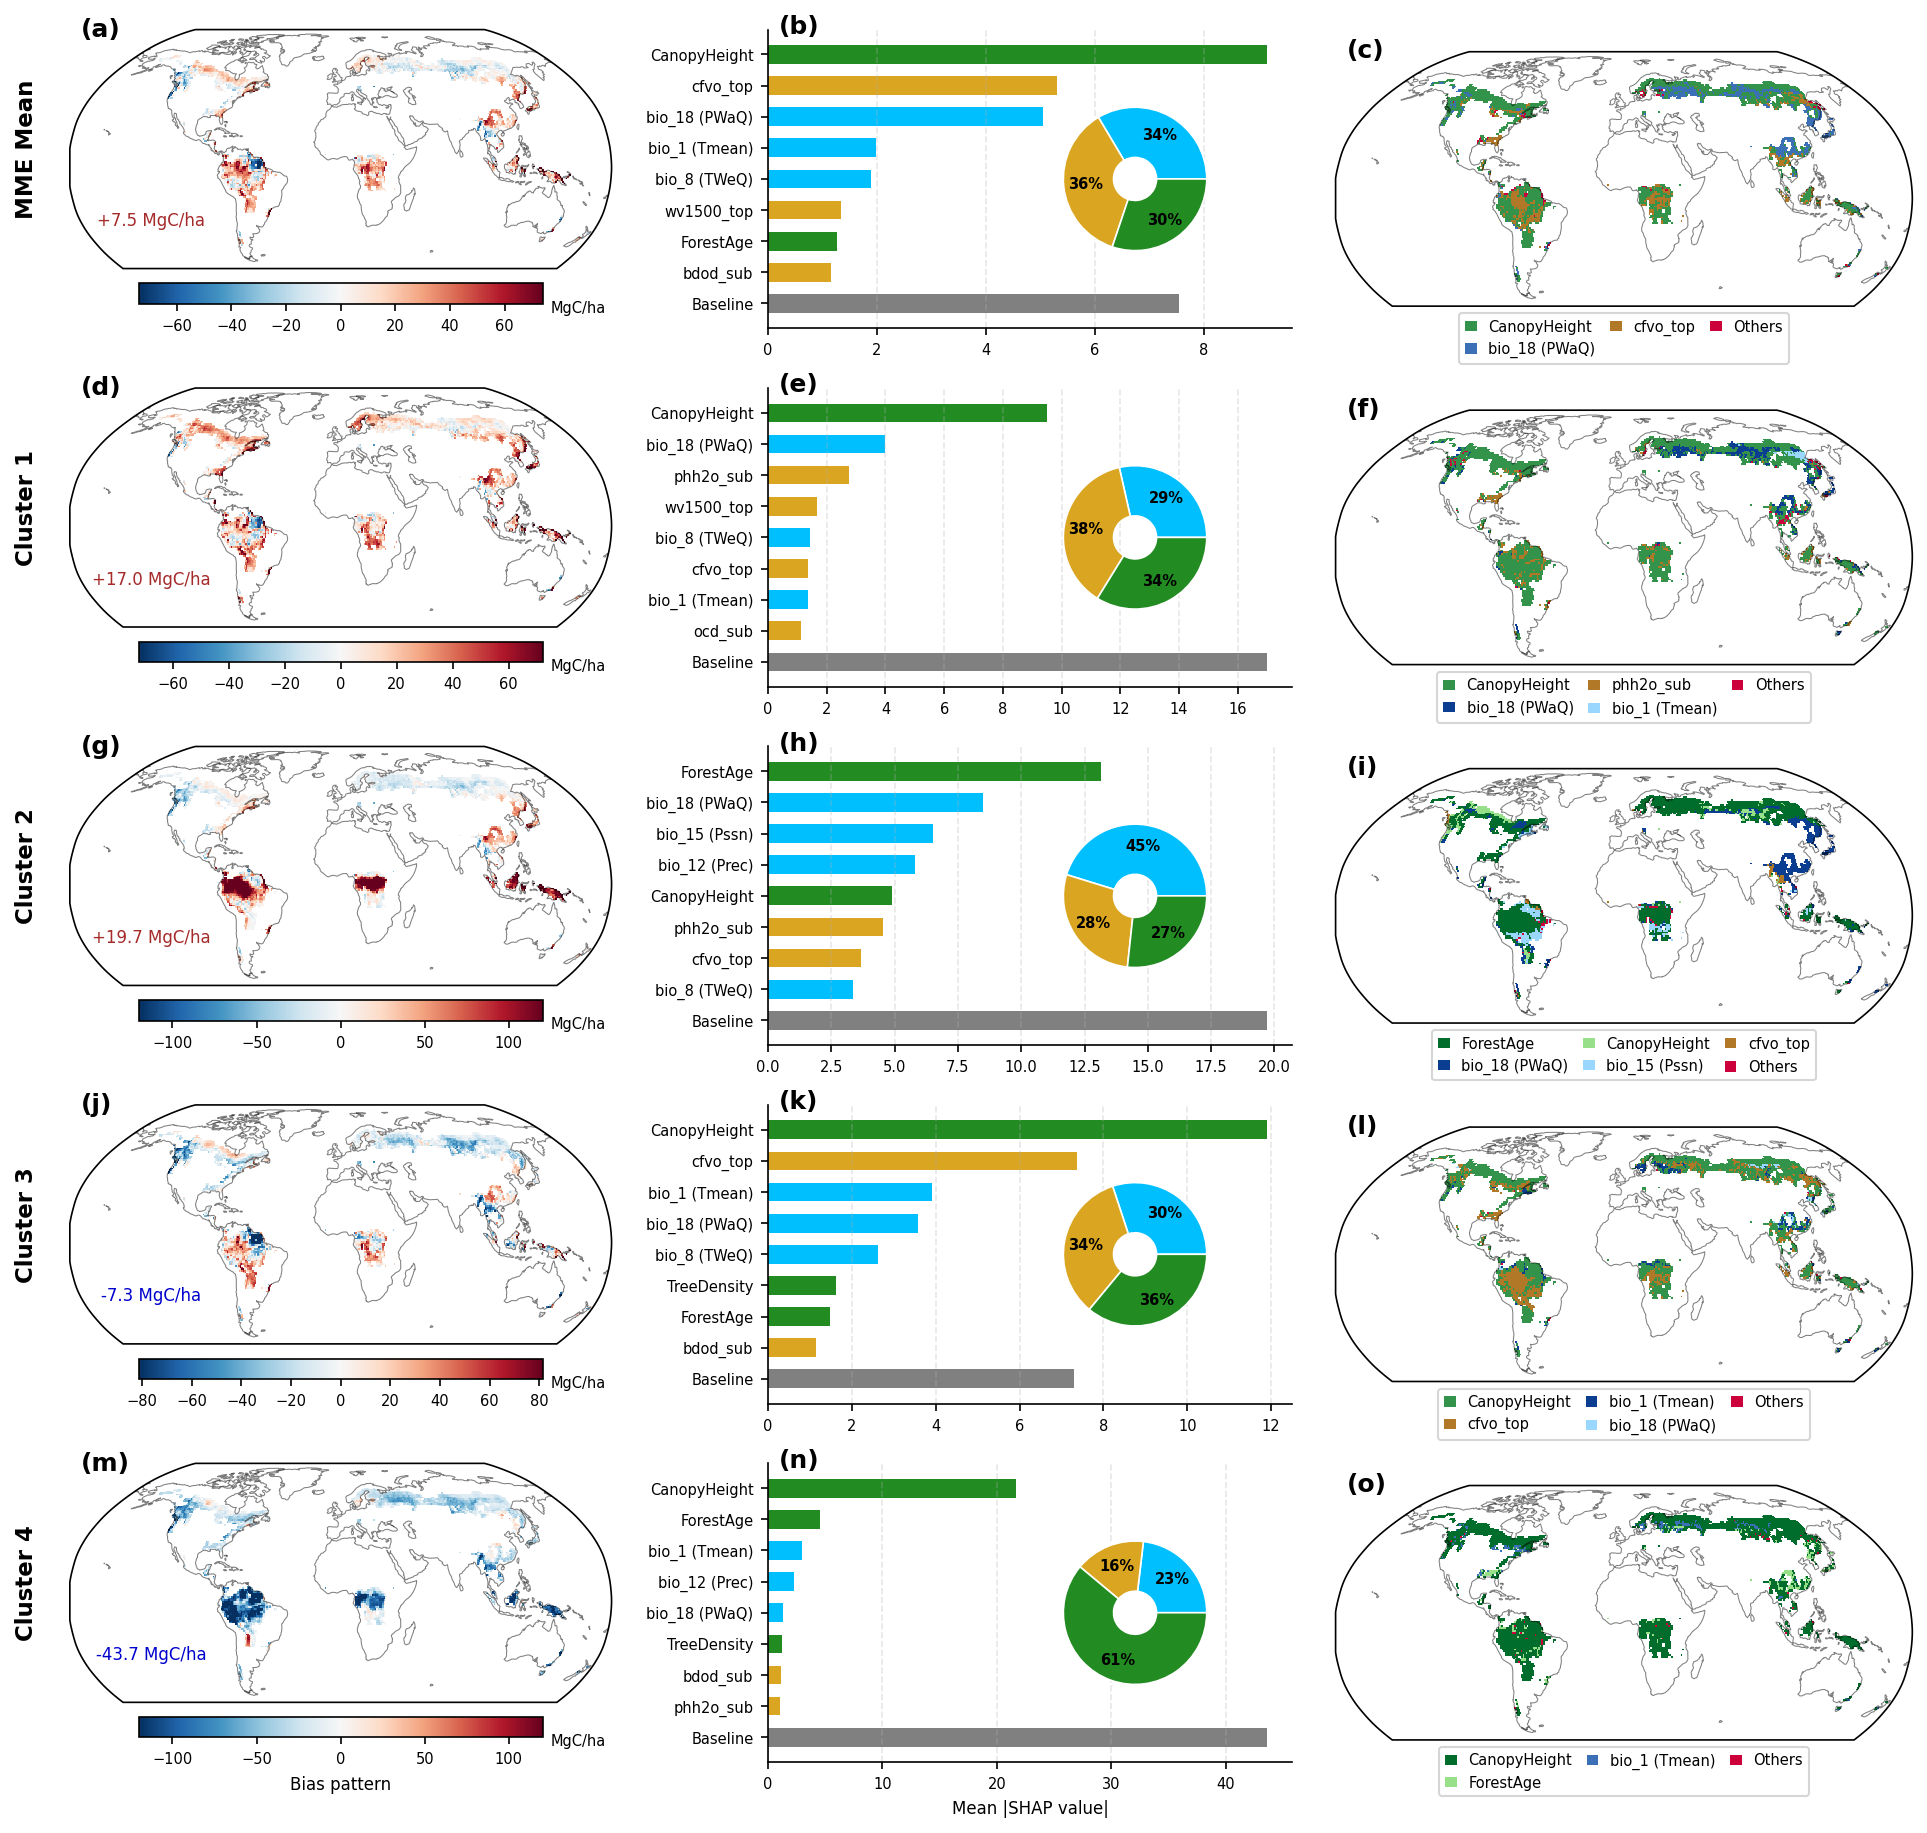

In [6]:
### ----- Figure 1: bias pattern, SHAP importance, and dominant-factor pattern ----- ###
plot_labels = list(results.keys())
nrows = len(plot_labels)
letters = iter(ascii_lowercase)
TOP_N = 8
OTHER_THRESHOLD = 1  # threshold for dominant factors (%)
OTHER_COLOR = "#CC003A"

fig = plt.figure(figsize=(16, 3*nrows), dpi=150)
gs = fig.add_gridspec(nrows, 4, width_ratios=[1.1, 0.1, 1.0, 1.1], wspace=0.1, hspace=0.2)

for row, label in enumerate(plot_labels):
    res = results[label]

    ### I. Bias pattern
    bias = res["bias"][30:]
    bias_lim = np.nanpercentile(np.abs(bias), 98)
    bias_lim = np.clip(bias_lim, 40, 120)

    ax0 = fig.add_subplot(gs[row, 0], projection=ccrs.Robinson())
    img0 = ax0.pcolormesh(
        lon, lat[30:], bias, cmap="RdBu_r", vmin=-bias_lim, vmax=bias_lim,
        transform=ccrs.PlateCarree(), shading="flat",
    )
    ax0.coastlines(linewidth=0.5, alpha=0.5)
    cbar0 = fig.colorbar(img0, ax=ax0, orientation="horizontal", shrink=0.7, pad=0.05)
    cbar0.ax.tick_params(labelsize=7)
    cbar0.ax.text(1.02, -0.2, "MgC/ha", transform=cbar0.ax.transAxes, va="center", fontsize=7)

    mean_bias = np.nanmean(bias)  # Mean bias
    ax0.text(0.15, 0.2, f"{mean_bias:+.1f} MgC/ha", transform=ax0.transAxes,
             ha="center", va="center", fontsize=8, color="brown" if mean_bias>0 else "mediumblue")

    panel_label(ax0, next(letters))
    ax0.text(-0.08, 0.5, label, transform=ax0.transAxes, rotation=90,
             ha="center", va="center", fontsize=11, fontweight="bold")
    if row == len(plot_labels)-1:
        cbar0.ax.set_xlabel("Bias pattern", fontsize=8)

    ### II. SHAP-based variable importance
    ax1 = fig.add_subplot(gs[row, 2])
    shap_imp = res.get("shap_importance", np.mean(np.abs(res["shap_values"]), axis=0))
    order = np.argsort(shap_imp)[::-1][:TOP_N]
    y = np.arange(len(order), 0, -1)
    baseline_imp = abs(float(res.get("baseline_value", np.mean(res["Y"]))))
    ax1.barh(y, shap_imp[order], color=[feature_colors[i] for i in order], height=0.6)
    ax1.barh(0, baseline_imp, color="gray", height=0.6)

    ax1.set_yticks(list(y) + [0], [selected[i] for i in order] + ["Baseline"], fontsize=7)
    ax1.set_ylim(-0.8, len(order) + 0.8)
    ax1.tick_params(axis="x", labelsize=7)
    ax1.grid(True, axis="x", linestyle="--", alpha=0.3)
    for spine in ["top", "right"]:
        ax1.spines[spine].set_visible(False)
    panel_label(ax1, next(letters))
    if row == len(plot_labels)-1:
        ax1.set_xlabel("Mean |SHAP value|", fontsize=8)

    group_imp = np.array([
        np.sum([shap_imp[i] for i, g in enumerate(selected_group) if g == group])
        for group in ["Climate", "Soil", "Vegetation"]
    ])
    ax_pie = ax1.inset_axes([0.4, 0.2, 0.6, 0.6])  # [x0, y0, width, height]
    ax_pie.pie(
        group_imp, colors=[color_type["Climate"], color_type["Soil"], color_type["Vegetation"]],
        autopct="%.0f%%", pctdistance=0.7, 
        textprops=dict(fontsize=7, weight="bold"),
        wedgeprops=dict(width=0.7, edgecolor="white", linewidth=0.8),
    )
    ax_pie.set_aspect("equal")

    ### III. Dominant-factor pattern based on SHAP values
    ax2 = fig.add_subplot(gs[row, 3], projection=ccrs.Robinson())
    main_map = res["main_var_map"]
    dominant_df = res.get("dominant_df")
    # 保留占比大于 OTHER_THRESHOLD 的变量
    keep_vars = dominant_df.loc[dominant_df["pixel_ratio"] >= OTHER_THRESHOLD, "variable_index"].astype(int).tolist()
    all_present = set(dominant_df["variable_index"].astype(int).tolist())
    other_vars = sorted(all_present - set(keep_vars))

    if len(all_present) == 0:
        ax2.text(0.5, 0.5, "No SHAP result", transform=ax2.transAxes, ha="center", va="center")
        panel_label(ax2, next(letters))
        continue

    clim_vars = [i for i in keep_vars if selected_group[i] == "Climate"]
    soil_vars = [i for i in keep_vars if selected_group[i] == "Soil"]
    veg_vars = [i for i in keep_vars if selected_group[i] == "Vegetation"]
    var_colors = {}
    for var_group, palette in [
        (clim_vars, ["#0B3D91", "#9AD7FF"]),
        (soil_vars, ["#8A4B08", "#FFD166"]),
        (veg_vars, ["#006D2C", "#98DF8A"]),
    ]:
        if len(var_group) == 1:
            var_colors[var_group[0]] = LinearSegmentedColormap.from_list("single", palette, N=10)(0.3)
        elif len(var_group) > 1:
            cmap_group = LinearSegmentedColormap.from_list("grp", palette, N=len(var_group))
            for j, idx in enumerate(var_group):
                var_colors[idx] = cmap_group(j)

    display_vars = keep_vars.copy()
    include_other = len(other_vars) > 0
    colors = [var_colors[i] for i in display_vars]
    labels = [selected[i] for i in display_vars]
    if include_other:
        colors.append(OTHER_COLOR)
        labels.append("Others")

    plot_map = np.full_like(main_map, np.nan, dtype=np.float32)
    for code, var_idx in enumerate(display_vars):
        plot_map[main_map == var_idx] = code
    if include_other:
        other_code = len(display_vars)
        plot_map[np.isin(main_map, other_vars)] = other_code

    cmap = ListedColormap(colors)
    bounds = np.arange(len(colors) + 1) - 0.5
    norm = BoundaryNorm(bounds, cmap.N)
    ax2.pcolormesh(
        lon, lat[30:], plot_map[30:], cmap=cmap, norm=norm,
        transform=ccrs.PlateCarree(), shading="flat",
    )
    ax2.coastlines(linewidth=0.5, alpha=0.5)
    panel_label(ax2, next(letters))

    handles = [Patch(facecolor=color, label=lab) for color, lab in zip(colors, labels)]
    ax2.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0),
               ncol=3, fontsize=7, frameon=True, columnspacing=1.0, handlelength=0.8)

plt.show(fig)  # fig 6
plt.close(fig)


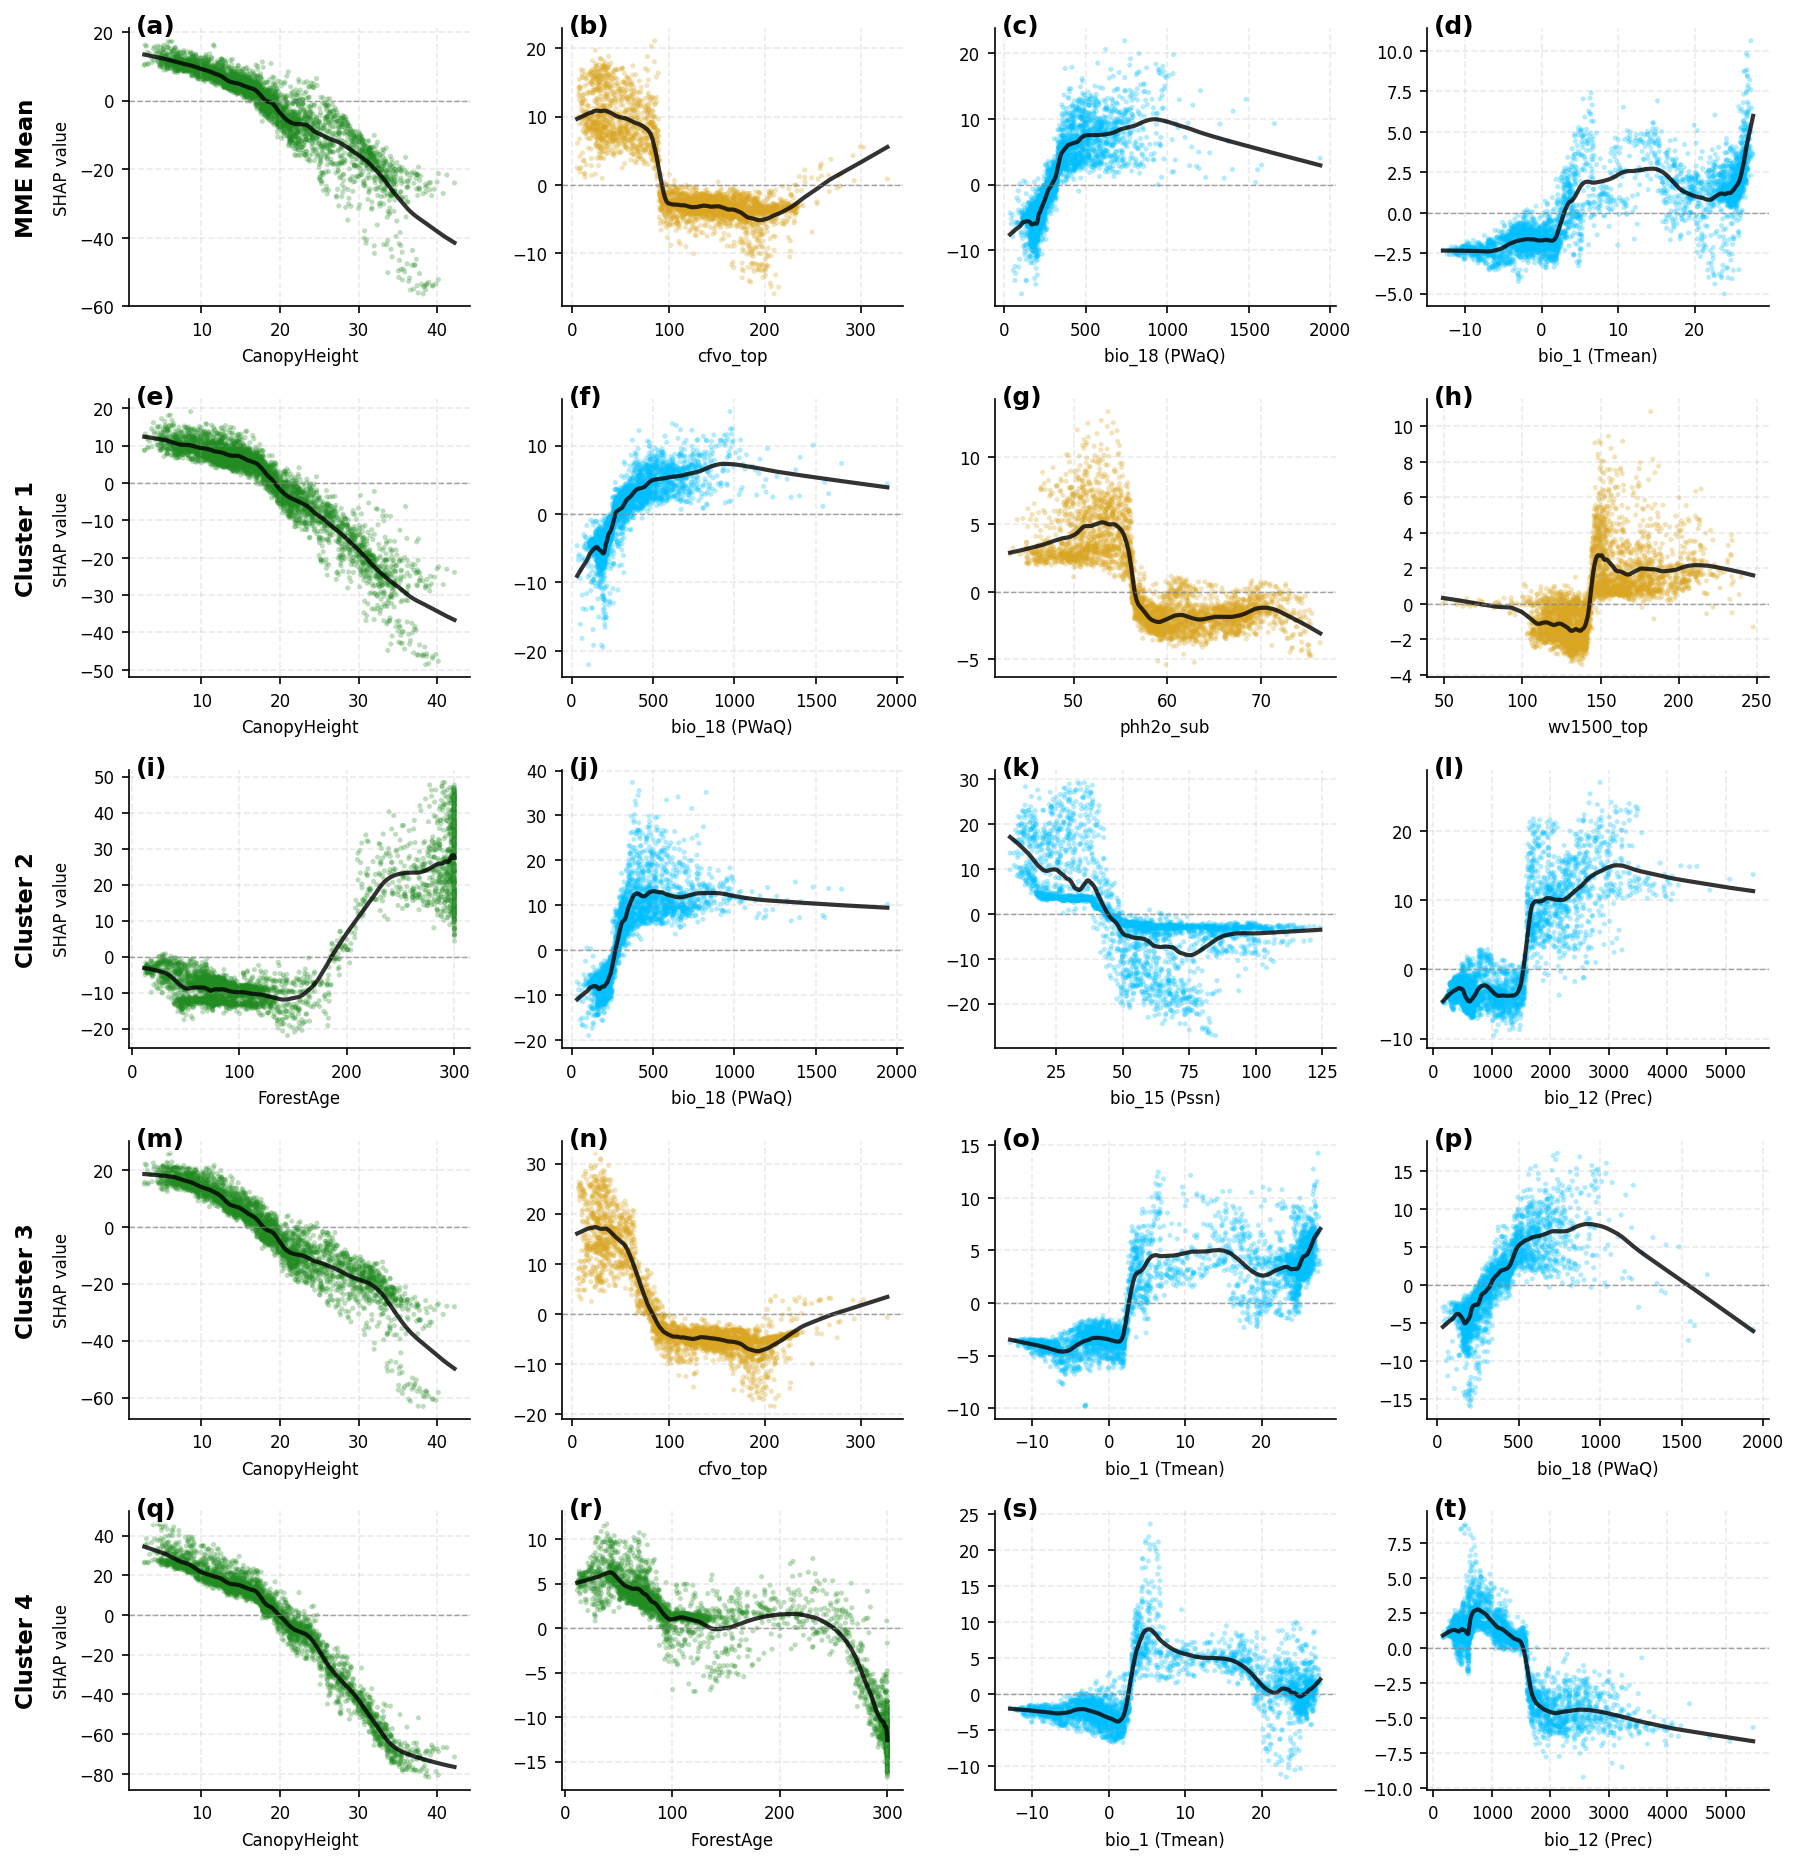

In [7]:
### ----- Figure 2: SHAP response curves for the top five variables in each group ----- ###
plot_labels = list(results.keys())
nrows = len(plot_labels)
TOP_RESPONSE = 4  # Show top N variables
letters = iter(ascii_lowercase)

fig, axs = plt.subplots(nrows, TOP_RESPONSE, figsize=(12, 2.5*nrows), dpi=150)

for row, label in enumerate(plot_labels):
    res = results[label]
    X = res["X"]
    shap_values = res["shap_values"]
    if shap_values is None:
        raise ValueError("SHAP values are required for response curves. Re-run the SHAP cell with RUN_SHAP=True.")

    shap_imp = res.get("shap_importance", np.mean(np.abs(shap_values), axis=0))
    order = np.argsort(shap_imp)[::-1][:TOP_RESPONSE]
    for col, feat_idx in enumerate(order):
        ax = axs[row, col]
        x = X[:, feat_idx]
        y = shap_values[:, feat_idx]
        valid = np.isfinite(x) & np.isfinite(y)
        x, y = x[valid], y[valid]

        ax.scatter(x, y, s=6, alpha=0.3, color=feature_colors[feat_idx], edgecolor="none")
        if x.size >= 20 and np.nanstd(x) > 0:
            smooth = lowess(y, x, frac=0.1, it=0, return_sorted=True)
            ax.plot(smooth[:, 0], smooth[:, 1], color="black", linewidth=2, alpha=0.8)

        ax.axhline(0, color="gray", linestyle="--", linewidth=0.7, alpha=0.7)
        ax.set_xlabel(selected[feat_idx], fontsize=8)
        if col == 0:
            ax.set_ylabel("SHAP value", fontsize=8)
            ax.text(-0.3, 0.5, label, transform=ax.transAxes, rotation=90,
                    ha="center", va="center", fontsize=11, fontweight="bold")
        else:
            ax.set_ylabel("")
        ax.tick_params(labelsize=8)
        ax.grid(True, linestyle="--", alpha=0.25)
        for spine in ["top", "right"]:
            ax.spines[spine].set_visible(False)
        panel_label(ax, next(letters))

fig.tight_layout(pad=1.0)
plt.show(fig)  # fig 7
plt.close(fig)


In [8]:
### ----- Shared functions for sensitivity analyses ----- ###
from sklearn.metrics import r2_score, mean_squared_error

SENSITIVITY_CV_FOLDS = 10
SENSITIVITY_LAT_SEP = 10
SENSITIVITY_LON_SEP = 20


def get_mask_coordinates(mask: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Return pixel-center latitude and longitude for valid mask pixels."""
    lat_center = (lat[:-1] + lat[1:]) / 2
    lon_center = (lon[:-1] + lon[1:]) / 2
    lat_grid, lon_grid = np.meshgrid(lat_center, lon_center, indexing="ij")
    return lat_grid[mask], lon_grid[mask]


def make_spatial_block_groups(lat_vec: np.ndarray, lon_vec: np.ndarray) -> np.ndarray:
    """Reproduce the randomized 10-degree by 20-degree blocks used by spatial CV."""
    lat_block = np.floor((lat_vec + 90) / SENSITIVITY_LAT_SEP).astype(int)
    lon_block = np.floor(lon_vec / SENSITIVITY_LON_SEP).astype(int)
    block_id = lat_block * 100 + lon_block

    unique_blocks = np.asarray(sorted(np.unique(block_id)))
    rng = np.random.default_rng(RANDOM_SEED)
    rng.shuffle(unique_blocks)
    block_to_fold = {block: i % SENSITIVITY_CV_FOLDS for i, block in enumerate(unique_blocks)}
    return np.array([block_to_fold[block] for block in block_id], dtype=int)


def make_group_splits(groups: np.ndarray):
    """Create leave-one-fold-out splits from precomputed spatial fold labels."""
    for group in sorted(np.unique(groups)):
        test_idx = np.where(groups == group)[0]
        train_idx = np.where(groups != group)[0]
        if len(test_idx) == 0 or len(train_idx) == 0:
            continue
        yield train_idx, test_idx


def dominant_factor_table(main_var: np.ndarray, feature_names: list[str],
                          feature_groups: list[str]) -> pd.DataFrame:
    """Summarize the dominant absolute-SHAP factor at every analyzed pixel."""
    mainvars, counts = np.unique(main_var, return_counts=True)
    n_pixels = len(main_var)
    return pd.DataFrame([
        {
            "variable_index": int(var),
            "variable": feature_names[int(var)],
            "group": feature_groups[int(var)],
            "pixels": int(count),
            "pixel_ratio": float(count / n_pixels * 100),
        }
        for var, count in sorted(zip(mainvars, counts), key=lambda x: x[1], reverse=True)
    ])


def assemble_sensitivity_result(label: str, model, X: np.ndarray, Y: np.ndarray,
                                bias: np.ndarray, mask: np.ndarray,
                                y_pred: np.ndarray, shap_values: np.ndarray,
                                base_values: np.ndarray, feature_names: list[str],
                                feature_groups: list[str]) -> dict:
    """Assemble model and SHAP outputs in the same layout used by the main analysis."""
    shap_values = np.asarray(shap_values, dtype=np.float32)
    main_var = np.argmax(np.abs(shap_values), axis=1)
    main_var_map = np.full_like(bias, np.nan, dtype=np.float32)
    main_var_map[mask] = main_var.astype(np.float32)

    bias_pred = np.full_like(bias, np.nan, dtype=np.float32)
    bias_pred[mask] = np.asarray(y_pred, dtype=np.float32)

    return {
        "label": label,
        "Model": model,
        "r2": float(r2_score(Y, y_pred)),
        "rmse": float(np.sqrt(mean_squared_error(Y, y_pred))),
        "bias": bias.astype(np.float32),
        "bias_pred": bias_pred,
        "mask": mask,
        "X": np.asarray(X, dtype=np.float32),
        "Y": np.asarray(Y, dtype=np.float32),
        "shap_values": shap_values,
        "shap_importance": np.mean(np.abs(shap_values), axis=0).astype(np.float32),
        "base_values": np.asarray(base_values, dtype=np.float32),
        "baseline_value": float(np.mean(base_values)),
        "main_var_map": main_var_map,
        "dominant_df": dominant_factor_table(main_var, feature_names, feature_groups),
    }


def plot_sensitivity_result(res: dict, feature_names: list[str],
                            feature_groups: list[str], title: str):
    """Plot the original Figure 1 diagnostics above the original Figure 2 responses."""
    top_n, top_response = 8, 4
    other_threshold, other_color = 1, "#CC003A"
    feature_colors_local = [color_type[group] for group in feature_groups]
    letters = iter(ascii_lowercase)

    fig = plt.figure(figsize=(16, 6), dpi=150)
    outer_gs = fig.add_gridspec(2, 1, height_ratios=[1.0, 1.0], hspace=0.3)
    # The two rows use independent column layouts: three panels above and four below.
    top_gs = outer_gs[0].subgridspec(1, 4, width_ratios=[1.1, 0.1, 1.0, 1.1], wspace=0.1)
    bottom_gs = outer_gs[1].subgridspec(1, 4, wspace=0.2)

    # --- First row: bias, SHAP importance, and dominant-factor pattern (original Figure 1) --- #
    bias = res["bias"][30:]
    bias_lim = np.clip(np.nanpercentile(np.abs(bias), 98), 40, 120)
    ax0 = fig.add_subplot(top_gs[0, 0], projection=ccrs.Robinson())
    img0 = ax0.pcolormesh(
        lon, lat[30:], bias, cmap="RdBu_r", vmin=-bias_lim, vmax=bias_lim,
        transform=ccrs.PlateCarree(), shading="flat",
    )
    ax0.coastlines(linewidth=0.5, alpha=0.5)
    cbar0 = fig.colorbar(img0, ax=ax0, orientation="horizontal", shrink=0.75, pad=0.05)
    cbar0.ax.tick_params(labelsize=7)
    cbar0.ax.text(1.02, -0.2, "MgC/ha", transform=cbar0.ax.transAxes, va="center", fontsize=7)
    mean_bias = np.nanmean(bias)
    ax0.text(0.15, 0.2, f"{mean_bias:+.1f} MgC/ha", transform=ax0.transAxes,
             ha="center", va="center", fontsize=8,
             color="brown" if mean_bias > 0 else "mediumblue")
    panel_label(ax0, next(letters))
    ax0.set_title("Model-Data Difference", fontsize=9)

    shap_imp = res["shap_importance"]
    order = np.argsort(shap_imp)[::-1][:top_n]
    y_pos = np.arange(len(order), 0, -1)
    ax1 = fig.add_subplot(top_gs[0, 2])
    ax1.barh(y_pos, shap_imp[order], color=[feature_colors_local[i] for i in order], height=0.6)
    ax1.barh(0, abs(res["baseline_value"]), color="gray", height=0.6)
    ax1.set_yticks(list(y_pos) + [0], [feature_names[i] for i in order] + ["Baseline"], fontsize=7)
    ax1.set_ylim(-0.8, len(order) + 0.8)
    ax1.set_xlabel("Mean |SHAP value|", fontsize=8)
    ax1.tick_params(axis="x", labelsize=7)
    ax1.grid(True, axis="x", linestyle="--", alpha=0.3)
    for spine in ["top", "right"]:
        ax1.spines[spine].set_visible(False)
    panel_label(ax1, next(letters))

    present_groups = [group for group in ["Climate", "Soil", "Vegetation"] if group in feature_groups]
    group_imp = np.array([
        np.sum([shap_imp[i] for i, group_i in enumerate(feature_groups) if group_i == group])
        for group in present_groups
    ])
    ax_pie = ax1.inset_axes([0.4, 0.2, 0.6, 0.6])
    ax_pie.pie(
        group_imp, colors=[color_type[group] for group in present_groups],
        autopct="%.0f%%", pctdistance=0.7,
        textprops=dict(fontsize=7, weight="bold"),
        wedgeprops=dict(width=0.7, edgecolor="white", linewidth=0.8),
    )
    ax_pie.set_aspect("equal")

    ax2 = fig.add_subplot(top_gs[0, 3], projection=ccrs.Robinson())
    main_map = res["main_var_map"]
    dominant_df = res["dominant_df"]
    keep_vars = dominant_df.loc[
        dominant_df["pixel_ratio"] >= other_threshold, "variable_index"
    ].astype(int).tolist()
    all_present = set(dominant_df["variable_index"].astype(int).tolist())
    other_vars = sorted(all_present - set(keep_vars))

    var_colors = {}
    for group, palette in [
        ("Climate", ["#0B3D91", "#9AD7FF"]),
        ("Soil", ["#8A4B08", "#FFD166"]),
        ("Vegetation", ["#006D2C", "#98DF8A"]),
    ]:
        group_vars = [i for i in keep_vars if feature_groups[i] == group]
        if len(group_vars) == 1:
            var_colors[group_vars[0]] = LinearSegmentedColormap.from_list("single", palette, N=10)(0.3)
        elif len(group_vars) > 1:
            cmap_group = LinearSegmentedColormap.from_list("group", palette, N=len(group_vars))
            for j, idx in enumerate(group_vars):
                var_colors[idx] = cmap_group(j)

    colors = [var_colors[i] for i in keep_vars]
    labels = [feature_names[i] for i in keep_vars]
    if other_vars:
        colors.append(other_color)
        labels.append("Others")

    plot_map = np.full_like(main_map, np.nan, dtype=np.float32)
    for code, var_idx in enumerate(keep_vars):
        plot_map[main_map == var_idx] = code
    if other_vars:
        plot_map[np.isin(main_map, other_vars)] = len(keep_vars)

    cmap = ListedColormap(colors)
    norm = BoundaryNorm(np.arange(len(colors) + 1) - 0.5, cmap.N)
    ax2.pcolormesh(
        lon, lat[30:], plot_map[30:], cmap=cmap, norm=norm,
        transform=ccrs.PlateCarree(), shading="flat",
    )
    ax2.coastlines(linewidth=0.5, alpha=0.5)
    panel_label(ax2, next(letters))
    ax2.set_title("Dominant Factor Pattern", fontsize=9)
    handles = [Patch(facecolor=color, label=label) for color, label in zip(colors, labels)]
    ax2.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0),
               ncol=3, fontsize=7, frameon=True, columnspacing=1.0, handlelength=0.8)

    # --- Second row: SHAP response curves (original Figure 2) --- #
    X, shap_values = res["X"], res["shap_values"]
    response_order = np.argsort(shap_imp)[::-1][:top_response]
    for col, feat_idx in enumerate(response_order):
        ax = fig.add_subplot(bottom_gs[0, col])
        x, y = X[:, feat_idx], shap_values[:, feat_idx]
        valid = np.isfinite(x) & np.isfinite(y)
        x, y = x[valid], y[valid]
        ax.scatter(x, y, s=6, alpha=0.3, color=feature_colors_local[feat_idx], edgecolor="none")
        if x.size >= 20 and np.nanstd(x) > 0:
            smooth = lowess(y, x, frac=0.1, it=0, return_sorted=True)
            ax.plot(smooth[:, 0], smooth[:, 1], color="black", linewidth=2, alpha=0.8)
        ax.axhline(0, color="gray", linestyle="--", linewidth=0.7, alpha=0.7)
        ax.set_xlabel(feature_names[feat_idx], fontsize=8)
        ax.set_ylabel("SHAP value" if col == 0 else "", fontsize=8)
        ax.tick_params(labelsize=8)
        ax.grid(True, linestyle="--", alpha=0.25)
        for spine in ["top", "right"]:
            ax.spines[spine].set_visible(False)
        panel_label(ax, next(letters))

    fig.suptitle(title, fontsize=12, fontweight="bold", y=0.95)
    plt.show(fig)
    plt.close(fig)


In [9]:
### ----- Sensitivity test 1: out-of-fold RF and SHAP using spatial CV blocks ----- ###
SPATIAL_SENSITIVITY_PATH = OUT_DIR / "RF_SHAP_SpatialCV_Sensitivity.joblib"
FORCE_RUN_SPATIAL_SENSITIVITY = False

base_res = results["MME Mean"]
X_spatial = base_res["X"]
Y_spatial = base_res["Y"]
mask_spatial = base_res["mask"]
bias_spatial = base_res["bias"]
lat_spatial, lon_spatial = get_mask_coordinates(mask_spatial)
spatial_fold_groups = make_spatial_block_groups(lat_spatial, lon_spatial)
spatial_splits = list(make_group_splits(spatial_fold_groups))

spatial_meta = {
    "data_signature": ANALYSIS_DATA_SIGNATURE,
    "selected": selected,
    "rf_kwargs": RF_KWARGS,
}

saved_spatial = None
if SPATIAL_SENSITIVITY_PATH.exists() and not FORCE_RUN_SPATIAL_SENSITIVITY:
    try:
        saved_spatial = load(SPATIAL_SENSITIVITY_PATH)
    except Exception as exc:
        print(f"Could not load spatial-sensitivity cache ({exc}); analysis will be rerun.")

if saved_spatial is not None and saved_spatial.get("meta") == spatial_meta:
    spatial_sensitivity_result = saved_spatial["result"]
    spatial_fold_models = saved_spatial["fold_models"]
    spatial_fold_metrics = saved_spatial["fold_metrics"]
    print(f"Loaded current spatial-CV sensitivity results from: `{SPATIAL_SENSITIVITY_PATH}`")
else:
    n_pixels, n_features = X_spatial.shape
    oof_pred = np.full(n_pixels, np.nan, dtype=np.float32)
    oof_shap = np.full((n_pixels, n_features), np.nan, dtype=np.float32)
    oof_base = np.full(n_pixels, np.nan, dtype=np.float32)
    fold_id = np.full(n_pixels, -1, dtype=np.int16)
    coverage = np.zeros(n_pixels, dtype=np.int8)
    spatial_fold_models, fold_rows = [], []

    for fold, (train_idx, test_idx) in enumerate(spatial_splits):
        print(f"Spatial fold {fold + 1}/{len(spatial_splits)}: "
              f"train={len(train_idx)}, test={len(test_idx)}")
        model = RandomForestRegressor(**RF_KWARGS)
        model.fit(X_spatial[train_idx], Y_spatial[train_idx])
        pred = model.predict(X_spatial[test_idx])

        explainer = shap.TreeExplainer(model, feature_names=selected)
        expl = explainer(X_spatial[test_idx])
        base_values = np.asarray(expl.base_values, dtype=np.float32)
        if base_values.ndim == 0:
            base_values = np.full(len(test_idx), float(base_values), dtype=np.float32)
        else:
            base_values = base_values.reshape(-1)

        oof_pred[test_idx] = pred.astype(np.float32)
        oof_shap[test_idx] = expl.values.astype(np.float32)
        oof_base[test_idx] = base_values
        fold_id[test_idx] = fold
        coverage[test_idx] += 1
        spatial_fold_models.append(model)

        fold_r2 = r2_score(Y_spatial[test_idx], pred)
        fold_rmse = np.sqrt(mean_squared_error(Y_spatial[test_idx], pred))
        print(f" > Val R2= {fold_r2:.3f}, RMSE= {fold_rmse:.2f}")
        fold_rows.append({
            "fold": fold + 1,
            "n_train": len(train_idx),  "n_test": len(test_idx),
            "R2": fold_r2,  "RMSE": fold_rmse,
        })

    if not np.all(coverage == 1):
        raise RuntimeError("Every pixel must occur exactly once in the spatial validation sets.")
    if not (np.all(np.isfinite(oof_pred)) and np.all(np.isfinite(oof_shap))):
        raise RuntimeError("Spatial out-of-fold predictions or SHAP values contain missing results.")

    spatial_sensitivity_result = assemble_sensitivity_result(
        "MME Mean - Spatial CV", spatial_fold_models,
        X_spatial, Y_spatial, bias_spatial, mask_spatial,
        oof_pred, oof_shap, oof_base, selected, selected_group,
    )
    spatial_sensitivity_result["fold_id"] = fold_id
    spatial_sensitivity_result["coverage"] = coverage
    spatial_fold_metrics = pd.DataFrame(fold_rows)
    dump({
        "meta": spatial_meta,
        "result": spatial_sensitivity_result,
        "fold_models": spatial_fold_models,
        "fold_metrics": spatial_fold_metrics,
    }, SPATIAL_SENSITIVITY_PATH, compress=3)
    print(f"\nSaved spatial-CV sensitivity results to: `{SPATIAL_SENSITIVITY_PATH}`")

coverage = spatial_sensitivity_result["coverage"]
if not np.all(coverage == 1):
    raise RuntimeError("Cached spatial sensitivity result does not cover every pixel exactly once.")
print(f"Validation coverage: {len(coverage)} pixels; unique counts= {np.unique(coverage)}")
print("Mean fold metrics (same aggregation as CV): "
      f"R2= {spatial_fold_metrics['R2'].mean():.3f} ± "
      f"{spatial_fold_metrics['R2'].std(ddof=0):.3f},  "
      f"RMSE= {spatial_fold_metrics['RMSE'].mean():.2f} ± "
      f"{spatial_fold_metrics['RMSE'].std(ddof=0):.2f}")
print("Pooled out-of-fold metrics: "
      f"R2= {spatial_sensitivity_result['r2']:.3f}, "
      f"RMSE= {spatial_sensitivity_result['rmse']:.2f}")


Spatial fold 1/10: train=2931, test=587
 > Val R2= 0.592, RMSE= 12.43
Spatial fold 2/10: train=3247, test=271
 > Val R2= 0.539, RMSE= 12.16
Spatial fold 3/10: train=3272, test=246
 > Val R2= 0.437, RMSE= 17.56
Spatial fold 4/10: train=2905, test=613
 > Val R2= 0.554, RMSE= 17.29
Spatial fold 5/10: train=3240, test=278
 > Val R2= 0.491, RMSE= 21.47
Spatial fold 6/10: train=3390, test=128
 > Val R2= 0.120, RMSE= 24.76
Spatial fold 7/10: train=3323, test=195
 > Val R2= 0.596, RMSE= 17.33
Spatial fold 8/10: train=3092, test=426
 > Val R2= 0.584, RMSE= 16.92
Spatial fold 9/10: train=3159, test=359
 > Val R2= 0.526, RMSE= 15.33
Spatial fold 10/10: train=3103, test=415
 > Val R2= 0.655, RMSE= 19.34

Saved spatial-CV sensitivity results to: `RF_SHAP_SpatialCV_Sensitivity.joblib`
Validation coverage: 3518 pixels; unique counts= [1]
Mean fold metrics (same aggregation as CV): R2= 0.509 ± 0.142,  RMSE= 17.46 ± 3.62
Pooled out-of-fold metrics: R2= 0.567, RMSE= 17.00


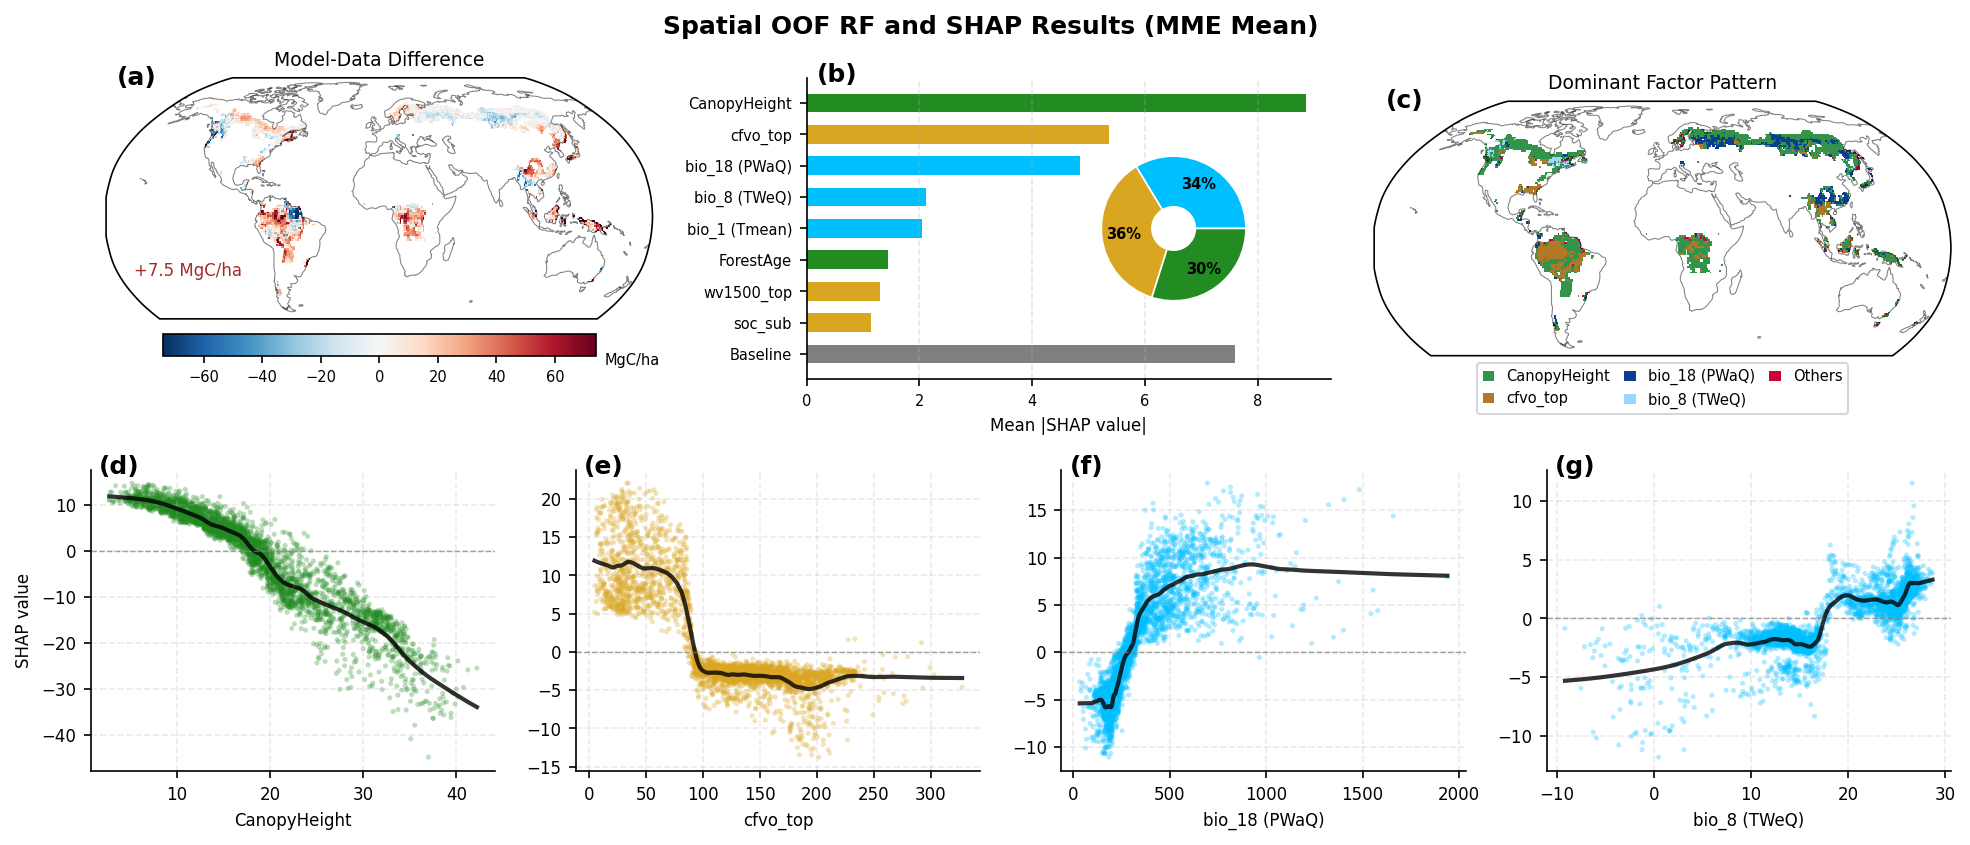

In [10]:
### ----- Sensitivity test 1 figure: spatial out-of-fold SHAP ----- ###
plot_sensitivity_result(
    spatial_sensitivity_result,
    selected,
    selected_group,
    "Spatial OOF RF and SHAP Results (MME Mean)",
)


In [11]:
### ----- Sensitivity test 2: RF and SHAP without vegetation variables ----- ###
NO_VEG_SENSITIVITY_PATH = OUT_DIR / "RF_SHAP_NoVegetation_Sensitivity.joblib"
FORCE_RUN_NO_VEG_SENSITIVITY = False

vegetation_idx = [i for i, group in enumerate(selected_group) if group == "Vegetation"]
no_veg_idx = [i for i in range(len(selected)) if i not in vegetation_idx]
selected_no_veg = [selected[i] for i in no_veg_idx]
selected_group_no_veg = [selected_group[i] for i in no_veg_idx]

# Reuse the same MME Mean pixels so that only the predictor set changes.
X_no_veg = base_res["X"][:, no_veg_idx]
Y_no_veg = base_res["Y"]
mask_no_veg = base_res["mask"]
bias_no_veg = base_res["bias"]
print(f"Removed vegetation variables: {[selected[i] for i in vegetation_idx]}")
print(f"No-vegetation data: X={X_no_veg.shape}, Y={Y_no_veg.shape}")

no_veg_meta = {
    "data_signature": ANALYSIS_DATA_SIGNATURE,
    "selected": selected_no_veg,
    "rf_kwargs": RF_KWARGS,
}

saved_no_veg = None
if NO_VEG_SENSITIVITY_PATH.exists() and not FORCE_RUN_NO_VEG_SENSITIVITY:
    try:
        saved_no_veg = load(NO_VEG_SENSITIVITY_PATH)
    except Exception as exc:
        print(f"Could not load no-vegetation cache ({exc}); analysis will be rerun.")

if saved_no_veg is not None and saved_no_veg.get("meta") == no_veg_meta:
    no_veg_sensitivity_result = saved_no_veg["result"]
    print(f"Loaded current no-vegetation results from: `{NO_VEG_SENSITIVITY_PATH}`")
else:
    no_veg_model = RandomForestRegressor(**RF_KWARGS)
    no_veg_model.fit(X_no_veg, Y_no_veg)
    no_veg_pred = no_veg_model.predict(X_no_veg)

    no_veg_explainer = shap.TreeExplainer(no_veg_model, feature_names=selected_no_veg)
    no_veg_expl = no_veg_explainer(X_no_veg)
    no_veg_base = np.asarray(no_veg_expl.base_values, dtype=np.float32)
    no_veg_sensitivity_result = assemble_sensitivity_result(
        "MME Mean - No Vegetation", no_veg_model,
        X_no_veg, Y_no_veg, bias_no_veg, mask_no_veg,
        no_veg_pred, no_veg_expl.values, no_veg_base,
        selected_no_veg, selected_group_no_veg,
    )
    dump({"meta": no_veg_meta, "result": no_veg_sensitivity_result},
         NO_VEG_SENSITIVITY_PATH, compress=3)
    print(f"Saved no-vegetation sensitivity results to: `{NO_VEG_SENSITIVITY_PATH}`")

print("No-vegetation model metrics: "
      f"R2= {no_veg_sensitivity_result['r2']:.3f}, "
      f"RMSE= {no_veg_sensitivity_result['rmse']:.2f}")


Removed vegetation variables: ['CanopyHeight', 'ForestAge', 'TreeDensity']
No-vegetation data: X=(3518, 21), Y=(3518,)
Saved no-vegetation sensitivity results to: `RF_SHAP_NoVegetation_Sensitivity.joblib`
No-vegetation model metrics: R2= 0.947, RMSE= 5.94


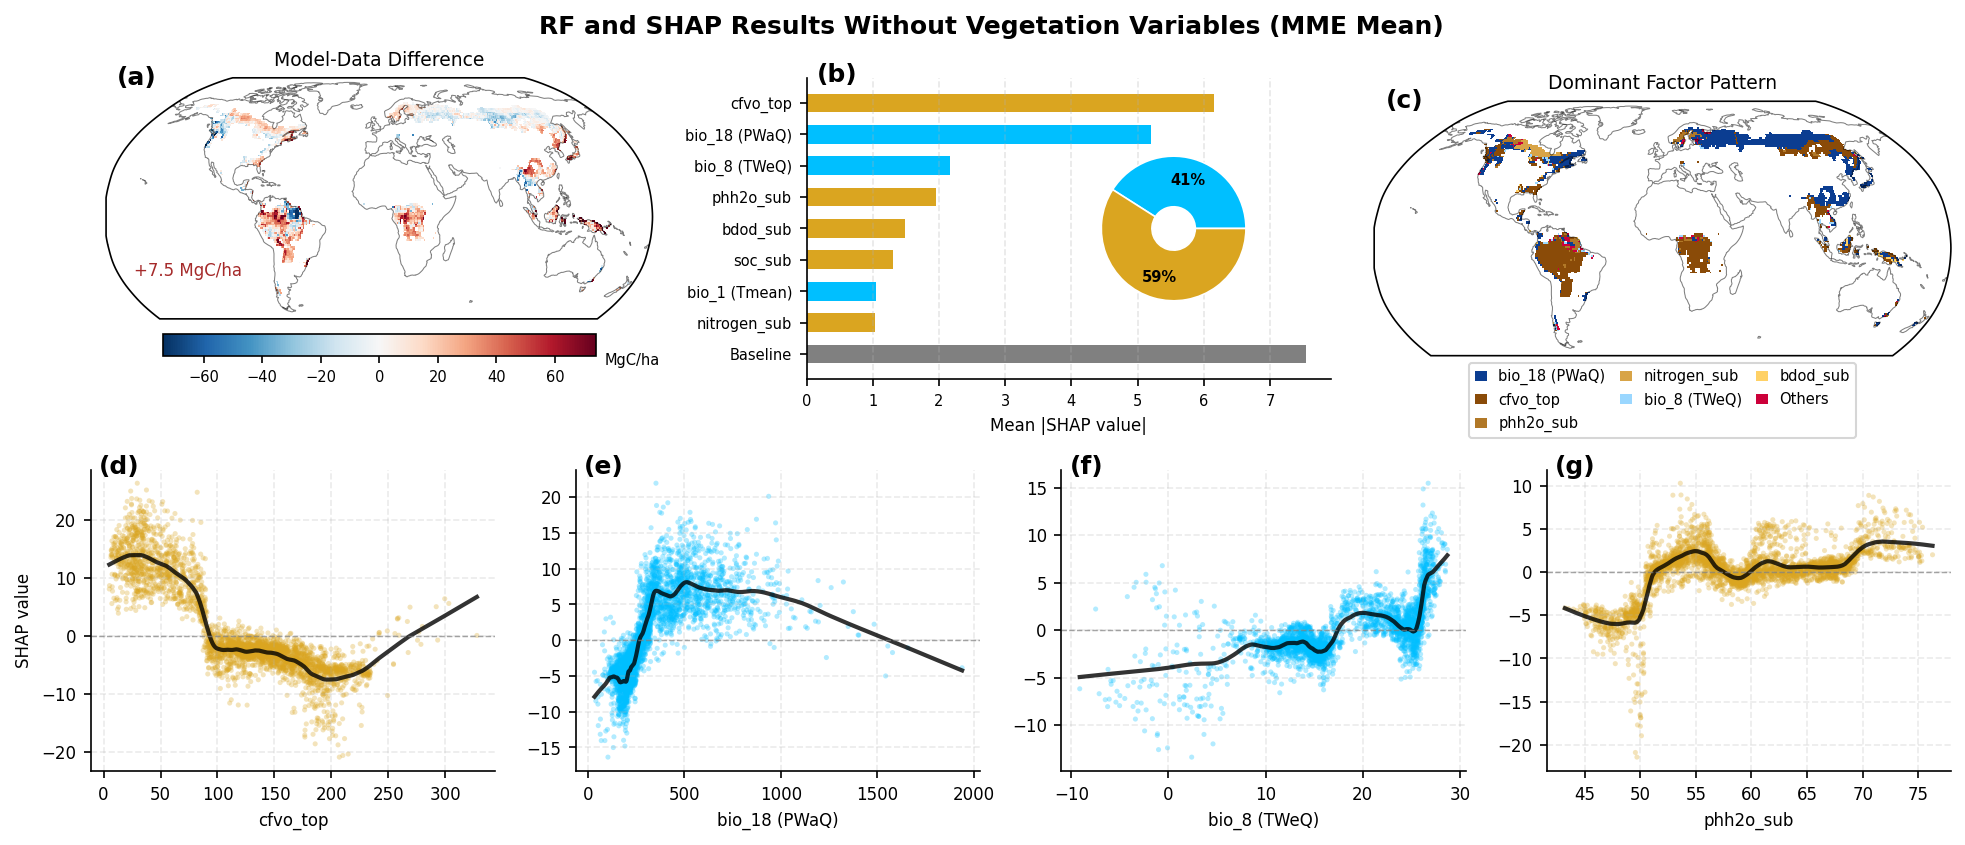

In [12]:
### ----- Sensitivity test 2 figure: SHAP without vegetation variables ----- ###
plot_sensitivity_result(
    no_veg_sensitivity_result,
    selected_no_veg,
    selected_group_no_veg,
    "RF and SHAP Results Without Vegetation Variables (MME Mean)",
)


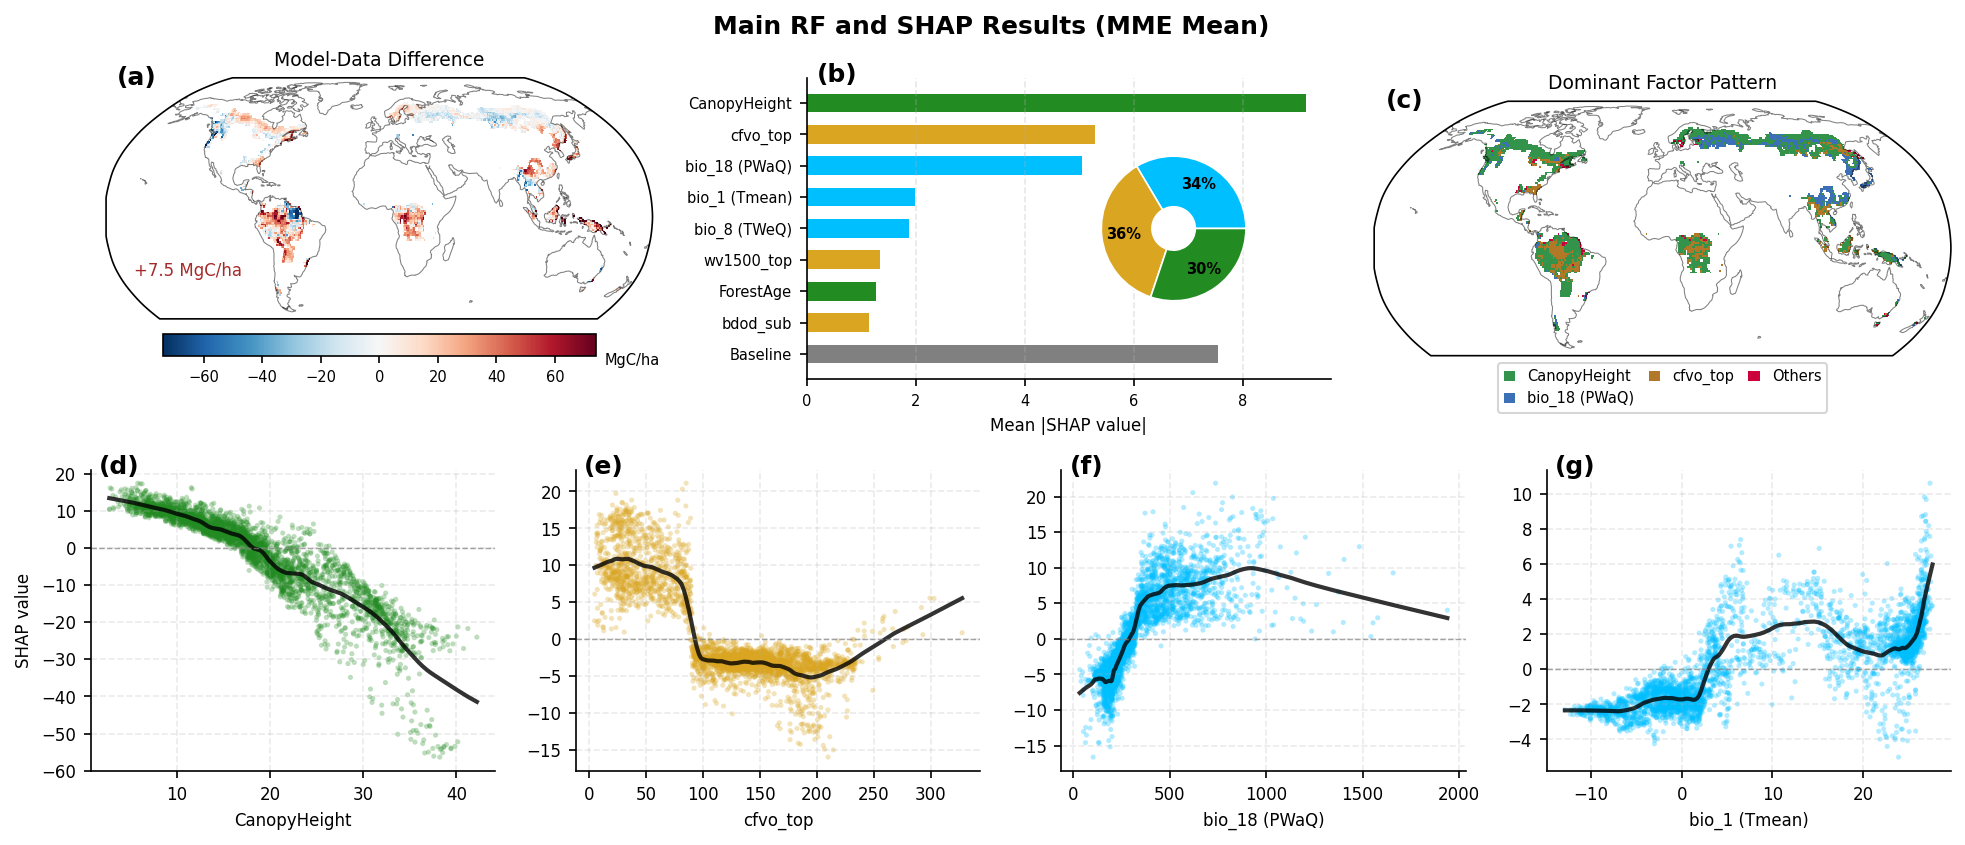

In [13]:
# summary of main RF results (MME Mean)
plot_sensitivity_result(
    results["MME Mean"], selected, selected_group,
    "Main RF and SHAP Results (MME Mean)",
)